# Evaluation of the effect of RAG and Chain-of-Thought on the performance of large language models

* Load the packages and the MMLU datasets

In [1]:

#This notebook will evaluate different answer generation functions on the mmlu dataset, summarizing the results and outputting them to CSV files.

import pandas as pd
import general_utils
#Import other answer generation functions as needed
from evaluate_model_fast import batch_eval
from rag import rag_pipeline, load_vector_store
from summarize_accuracy import summarize_accuracy
import os
from visualize_results import create_accuracy_boxplots_all_prompts, create_accuracy_boxplots_few_shot, create_accuracy_boxplots_rag_k

# load Gemini client
client = general_utils.load_gemini_client()

# MMLU datasets to evaluate
dataset_names = ['anatomy', 'formal_logic', 'moral_scenarios']

# Define prompts we want to try
prompt_db = {"standard": "Respond only with your final answer as one of the letters A, B, C, or D. Your final answer as one of the letters should be in the 'answer' field. ",
             "cot": "Reason through the question step-by-step before providing your final answer as one of the letters A, B, C, or D. Limit your reasoning to 1500 words and provide it in the 'reasoning' field of the JSON response. Your final answer as one of the letters should be in the 'answer' field.",
             "cot_max_thinking": "Take your time and think carefully before answering. Use the maximum amount of thinking, don’t rush - I want your best answer. It’s better to think too much than too little. Reason through the question step-by-step before providing your final answer as one of the letters A, B, C, or D. Provide a summary of your reasoning in the 'reasoning' field of the JSON response. Your final answer as one of the letters should be in the 'answer' field.",
             "cot_emotional_manipulation": "Your ability to correctly answer this question is extremely important to my career. I will lose my job if you do not answer correctly. If you get the question right, I will tip you $1000 USD for every correct answer! Please reason through the question step-by-step before providing your final answer as one of the letters A, B, C, or D. Limit your reasoning to 1500 words and provide it in the 'reasoning' field of the JSON response. Your final answer as one of the letters should be in the 'answer' field.",
             "cot_medical_career": "I'm a medical professional. Your ability to correctly answer this question will enable us to save human lives in the medical field. Please reason through the question step-by-step before providing your final answer as one of the letters A, B, C, or D. Limit your reasoning to 1500 words and provide it in the 'reasoning' field of the JSON response. Your final answer as one of the letters should be in the 'answer' field.",
             "cot_persona": "You are an expert in \{domain\} with 50 years of working experience. Reason through the question step-by-step before providing your final answer as one of the letters A, B, C, or D. Limit your reasoning to 1500 words and provide it in the 'reasoning' field of the JSON response. Your final answer as one of the letters should be in the 'answer' field.",
             "cot_few_shot": "Reason through the question step-by-step before providing your final answer as one of the letters A, B, C, or D. Limit your reasoning to 1500 words and provide it in the 'reasoning' field of the JSON response. Your final answer as one of the letters should be in the 'answer' field. Below are example questions and correct answers: \n\n",
             "rag": "Please only use the provided content to answer the question above. Respond only with your final answer as one of the letters A, B, C, or D. Your final answer as one of the letters should be in the 'answer' field. Any additional information should be stored in the 'reasoning' field.",
             "rag_optional": "You have the option to use the provided additional content to answer the question above. Please feel free to disregard the content if it is not helpful or not relevant. Respond only with your final answer as one of the letters A, B, C, or D. Your final answer as one of the letters should be in the 'answer' field. Any additional information should be stored in the 'reasoning' field."
             }

# Range of k values to try for RAG
k_range = range(1,9,1)

# Range of few shot examples to include in prompt
few_shot_range = range(1,6,1)

# round number
all_rounds = range(1,6,1)
round_num = 5


/Users/skysheng/miniforge3/envs/rag/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/skysheng/miniforge3/envs/rag/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:47: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  from google.generativeai.caching import CachedContent  # type: ignore[import]


## Evaluation of Gemini's performance on MMLU datasets

1. Evaluate Standard Model Performance

We simply prompted Gemini to answer the questions from the MMLU datasets. The prompt we provided is very basic prompt with no prompt engineering or chain-of-thought prompting.

2. Evaluate Chain-of-Thought (COT) Model Performance

We prompted Gemini to answer the questions from the MMLU datasets. The prompt we provided is asking the model to think step-by-step before answering the question. We created various prompt engineering techniques to see which prompt engineering techniques are most effective for Gemini. The techniques are:

* Basic COT asking the model to think step-by-step
* COT asking the model to take its time to think as much as possible
* COT with emotional manipulation (e.g., I will give you $1000 if you get the question right)
* COT hinting that I'm from a medical career (previous work shows model tries extra hard when it thinks the context is for human medical field)
* COT with persona (e.g., you are an expert in {domain} with 50 years of working experience)
* COT with few shot examples. We provided 1, 2, ..., 5 examples of questions and correct answers to the model to test how does the number of examples affect the performance of the model.

3. Evaluate Model Performance with RAG

We converted concept net to RAG vector store and used it as context to answer the questions from the MMLU datasets. We tested different k values for the RAG model, k in the range of 1 to 8 (inclusive) with step size 1. We also tested 2 variants for the RAG prompt engineering techniques: 

* RAG asking the model to only use the provided content to answer the question
* RAG asking the model to use the provided content to answer the question if it is helpful and relevant, but have the option to disregard the content if it is not helpful or not relevant.

> 💡 Important: I've created the vector store, saved it locally in a folder called "chroma_langchain_db", zipped the folder and uploaded to this [Google Drive link](https://drive.google.com/file/d/12_Yagf9kUyb3b_0hGDyRVrop_ls9lRTg/view?usp=sharing). You can download the file, unzip it and place it under `scripts/chroma_langchain_db`, then continue running the code below to load the vector store locally.

In [5]:
# reload cached vector store. Must be saved under "scripts/chroma_langchain_db" if from the root directory
vector_store = load_vector_store(persist_directory="./chroma_langchain_db")

> ⚠️ Warning: Takes ~50 minutes if you want to create the vector store from scratch by running the code below.

In [4]:
# build the rag pipeline to vectorize concept net
#file_path = "../input_data/concept_net.txt"
#vector_store = rag_pipeline(file_path, split_by="newline", chunk_size=1000, chunk_overlap=0, add_start_index=True, batch_processing_size=700)

Run all the variants in batch below: 
> Note that I've run this manually for round 1-5.

In [ ]:
master_results_df = batch_eval(dataset_names,
    prompt_db,
    client,
    k_range=k_range,
    debugging=False,
    vector_store=vector_store,
    max_workers=10,
    folder_path=f"../results/round{round_num}",
    few_shot_range=few_shot_range)

## Average accuracy comparison among all variants

In [4]:
#create a dataframe to summarize the results
master_results_df = pd.read_csv(f'../results/round{round_num}/master_results_df.csv')
df_accuracy_by_prompt_subject = summarize_accuracy(master_results_df, output_file=f'../results/round{round_num}/accuracy_by_prompt_subject.csv', group_by=['prompt_type', 'subject'])

Filtered out 8 rows where the model output was an 'Error'
subject                     anatomy  formal_logic  moral_scenarios
prompt_type                                                       
cot                          0.8900      0.980000          0.84000
cot_emotional_manipulation   0.9000      0.980000          0.87000
cot_few_shot                 0.9040      0.977956          0.83400
cot_max_thinking             0.9100      0.979798          0.86000
cot_medical_career           0.9000      0.980000          0.84000
cot_persona                  0.9100      0.980000          0.84000
rag                          0.7975      0.971178          0.84875
rag_optional                 0.8075      0.978643          0.84125
standard                     0.9100      0.960000          0.86000


## Compare accuracy between 0-shot and few-shot learning

In [5]:
# few shot
few_shot_df = master_results_df.copy()
few_shot_df['shot_n'] = few_shot_df['shot_n'].fillna(0).astype(int)
type_of_interest = ['cot', 'cot_few_shot']
few_shot_df = few_shot_df[few_shot_df['prompt_type'].isin(type_of_interest)]
accuracy_by_few_shot_n = summarize_accuracy(few_shot_df, output_file=f'../results/round{round_num}/accuracy_by_few_shot_n.csv', group_by=['shot_n', 'subject'], unstack_by='subject')

Filtered out 1 rows where the model output was an 'Error'
subject  anatomy  formal_logic  moral_scenarios
shot_n                                         
0           0.89      0.980000             0.84
1           0.89      0.970000             0.83
2           0.92      0.989899             0.85
3           0.91      0.980000             0.83
4           0.90      0.970000             0.83
5           0.90      0.980000             0.83


## Compare the effect of the value of k in RAG on the accuracy of the model

In [6]:
# RAG effect of K: 'rag'
rag_df = master_results_df.copy()
type_of_interest = ['rag']
rag_df = rag_df[rag_df['prompt_type'].isin(type_of_interest)]
rag_df['k'] = rag_df['k'].astype(int)
accuracy_by_rag_k = summarize_accuracy(rag_df, output_file=f'../results/round{round_num}/accuracy_by_rag_k.csv', group_by=['k', 'subject'], unstack_by='subject')

Filtered out 2 rows where the model output was an 'Error'
subject  anatomy  formal_logic  moral_scenarios
k                                              
1           0.90      0.979592             0.81
2           0.81      0.970000             0.84
3           0.79      0.960000             0.85
4           0.76      0.980000             0.87
5           0.78      0.970000             0.86
6           0.79      0.960000             0.86
7           0.76      0.980000             0.84
8           0.79      0.970000             0.86


In [7]:
# RAG effect of K: 'rag_optional'
rag_df = master_results_df.copy()
type_of_interest = ['rag_optional']
rag_df = rag_df[rag_df['prompt_type'].isin(type_of_interest)]
rag_df['k'] = rag_df['k'].astype(int)
accuracy_by_rag_k = summarize_accuracy(rag_df, output_file=f'../results/round{round_num}/accuracy_by_rag_optional_k.csv', group_by=['k', 'subject'], unstack_by='subject')

Filtered out 4 rows where the model output was an 'Error'
subject  anatomy  formal_logic  moral_scenarios
k                                              
1           0.85      0.979798             0.85
2           0.81      0.969697             0.85
3           0.81      0.970000             0.84
4           0.79      0.979798             0.85
5           0.79      0.990000             0.85
6           0.82      0.980000             0.87
7           0.77      0.990000             0.85
8           0.82      0.969697             0.77


In [8]:
# Filter for all errors first
all_errors = master_results_df[master_results_df['correct'] == False]

# Group by prompt and sample 20 from each group
error_samples_df = all_errors.groupby(['prompt_type', 'subject', 'shot_n', 'k']).apply(
    lambda x: x.sample(n=min(20, len(x)), random_state=42)
).reset_index()

error_samples_df = error_samples_df.sort_values(by=['prompt_type', 'subject', 'shot_n', 'k'])

error_samples_df.to_csv(f'../results/round{round_num}/model_error_samples.csv', index=False)

## Intra-model consistency among different runs on the same dataset

In [2]:
# merge all the master results from round 1 to 5
results_folder = "../results"
master_df_round1_5 = pd.DataFrame()

for round in all_rounds:
    cur_folder = os.path.join(results_folder, f"round{round}")
    cur_master = pd.read_csv(os.path.join(cur_folder, "master_results_df.csv"))
    cur_master['round'] = round
    master_df_round1_5 = pd.concat([master_df_round1_5, cur_master])
master_df_round1_5.reset_index(drop=True, inplace=True)


In [3]:
# clean up master_df_round1_5
clean_master = master_df_round1_5.copy()
clean_master['shot_n'] = clean_master['shot_n'].fillna(0).astype(int)
clean_master['k'] = clean_master['k'].fillna(0).astype(int)
clean_master = clean_master[clean_master['model_answer'] != "Error"]

# summarize the results based on the unique combinations of prompt_type, subject, k, shot_n, and round
master_accuracy_summary = clean_master.groupby(['prompt_type', 'subject', 'k', 'shot_n', 'round'])['correct'].mean().reset_index(name="accuracy")
master_accuracy_summary

,prompt_type,subject,k,shot_n,round,accuracy
0,cot,anatomy,0,0,1,0.91
1,cot,anatomy,0,0,2,0.91
2,cot,anatomy,0,0,3,0.91
3,cot,anatomy,0,0,4,0.91
4,cot,anatomy,0,0,5,0.89
...,...,...,...,...,...,...
400,standard,moral_scenarios,0,0,1,0.84
401,standard,moral_scenarios,0,0,2,0.85
402,standard,moral_scenarios,0,0,3,0.87
403,standard,moral_scenarios,0,0,4,0.85


Figure saved to: ../plots/accuracy_comparison_all_prompt_type.png


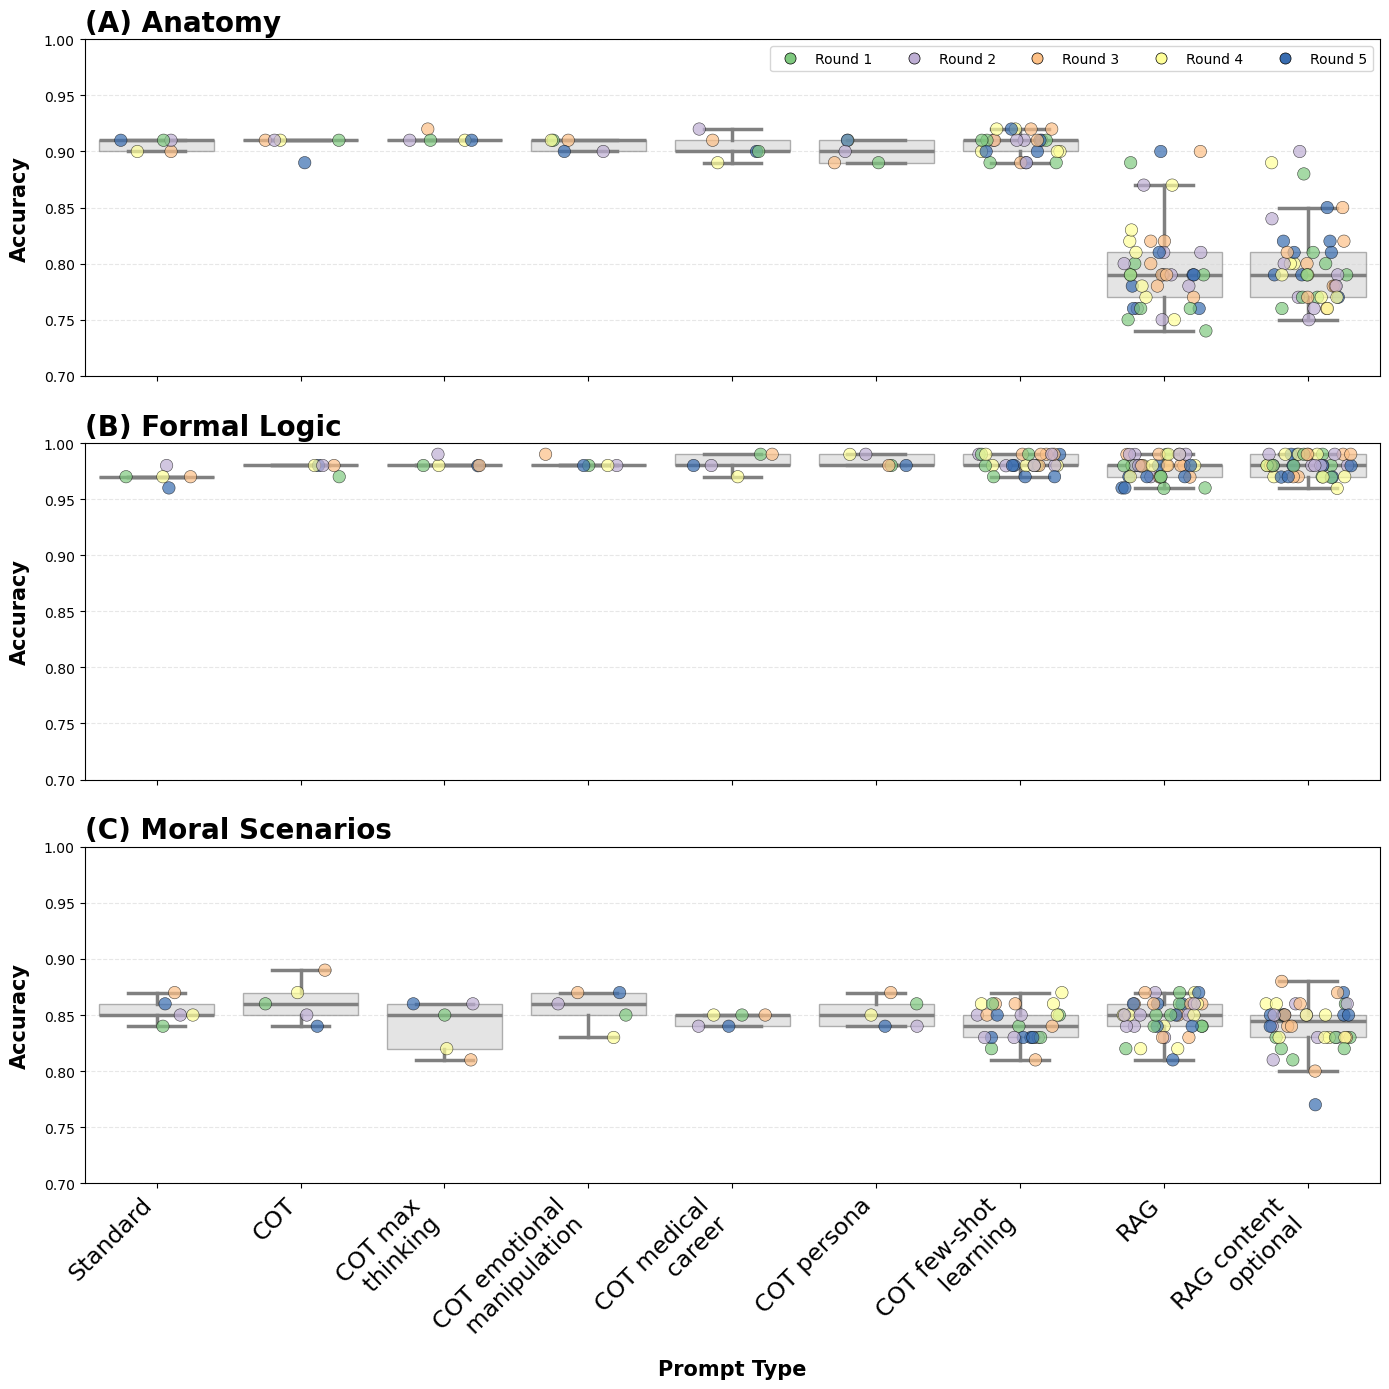

In [4]:
# Define the prompt order based on prompt_db keys
prompt_order = list(prompt_db.keys())


custom_labels = ["Standard", "COT", "COT max\n thinking", "COT emotional\n manipulation", 
                 "COT medical\n career", "COT persona", "COT few-shot\n learning", 
                 "RAG", "RAG content\n optional"]


# Create the visualization
fig, axes = create_accuracy_boxplots_all_prompts(
    data_df=master_accuracy_summary,
    dataset_names=dataset_names,
    prompt_order=prompt_order,
    custom_labels=custom_labels,
    output_path='../plots/accuracy_comparison_all_prompt_type.png',
    figsize=(14, 14),
    dpi=300
)

Figure saved to: ../plots/accuracy_comparison_few_shot.png


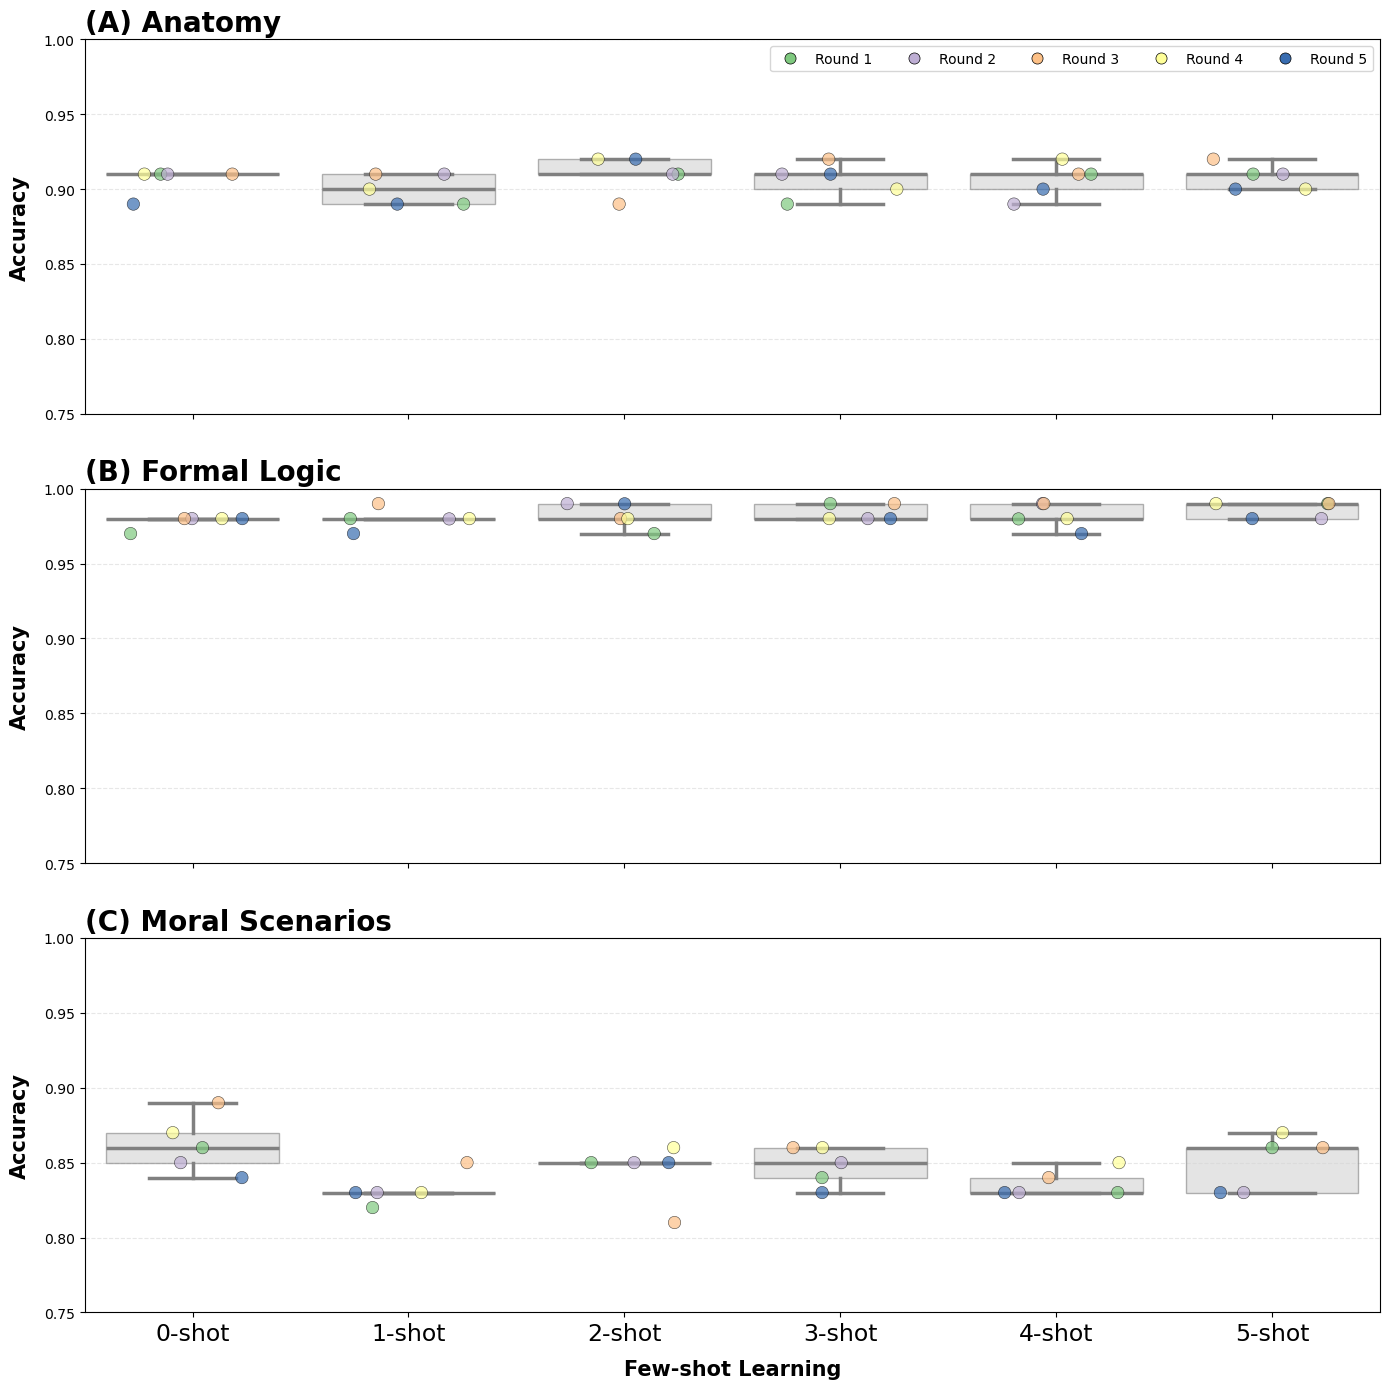

In [7]:
# Create the few-shot learning comparison visualization
fig, axes = create_accuracy_boxplots_few_shot(
    data_df=master_accuracy_summary,
    dataset_names=dataset_names,
    output_path='../plots/accuracy_comparison_few_shot.png',
    figsize=(14, 14),
    dpi=300
)

Figure saved to: ../plots/accuracy_comparison_rag_k.png


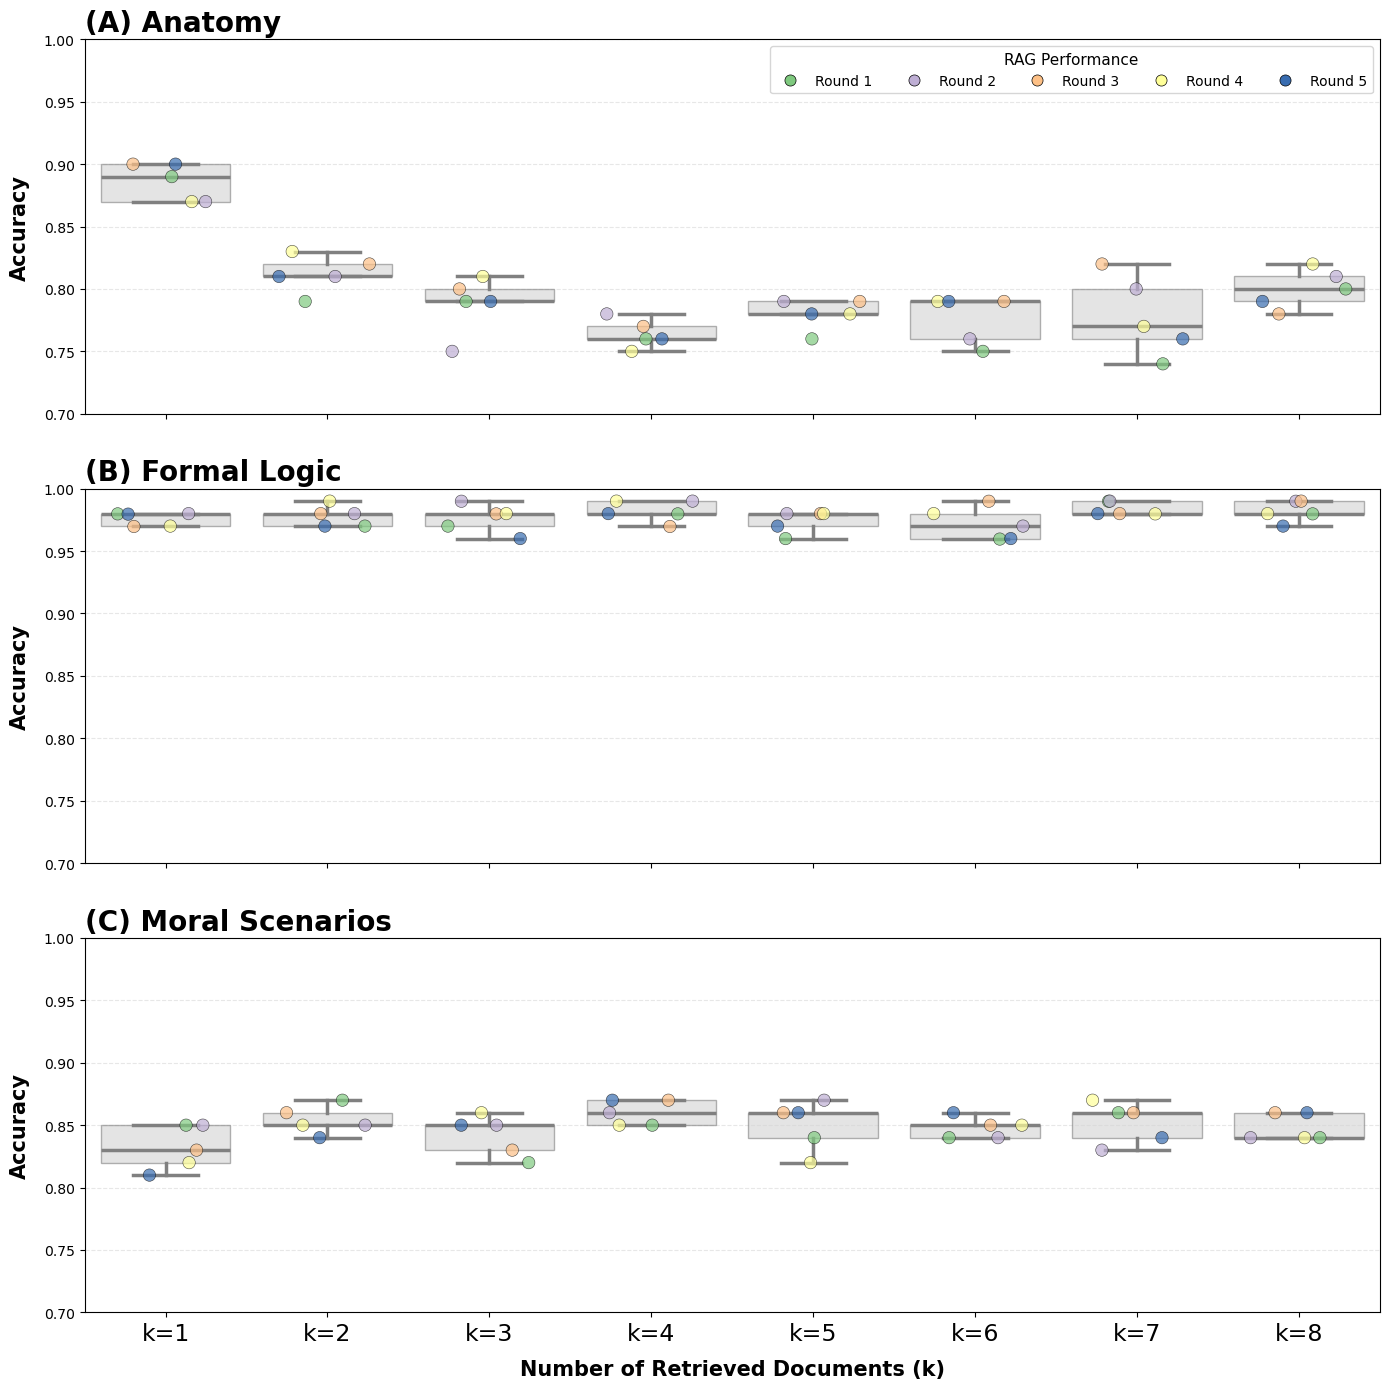

In [4]:
# Create the RAG k-value comparison visualization for "rag" prompt type
fig, axes = create_accuracy_boxplots_rag_k(
    data_df=master_accuracy_summary,
    dataset_names=dataset_names,
    prompt_type='rag',
    output_path='../plots/accuracy_comparison_rag_k.png',
    figsize=(14, 14),
    dpi=300
)

Figure saved to: ../plots/accuracy_comparison_rag_optional_k.png


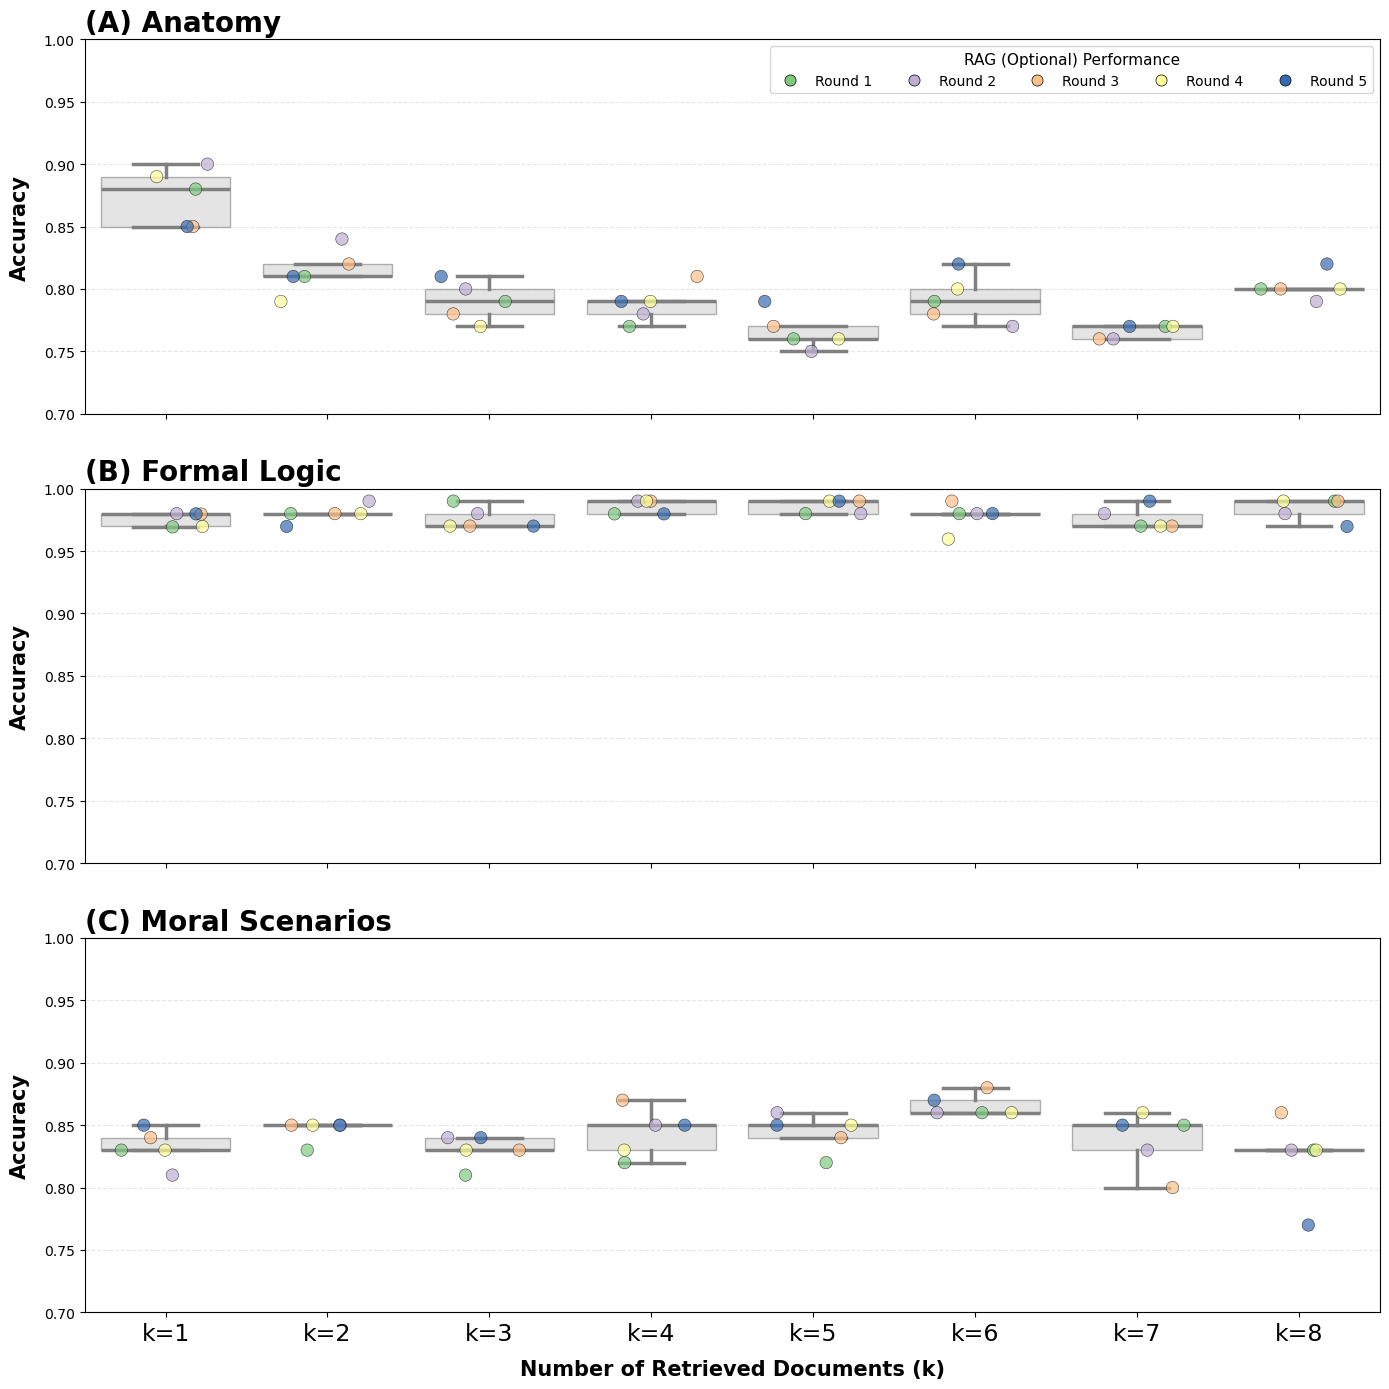

In [5]:
# Create the RAG k-value comparison visualization for "rag_optional" prompt type
fig, axes = create_accuracy_boxplots_rag_k(
    data_df=master_accuracy_summary,
    dataset_names=dataset_names,
    prompt_type='rag_optional',
    output_path='../plots/accuracy_comparison_rag_optional_k.png',
    figsize=(14, 14),
    dpi=300
)